# Trace the exchange that led to a delta

This walkthrough follows the OP's delta-award comment for published pair `#2860` back to the top-level reply. PostgreSQL supplies the parent links and speaker metadata. The local Parquet release supplies the full comment text. Depth 0 is the opening reply. Each higher depth is a direct reply to the previous turn on this path.

In [1]:
from contextlib import closing
from pathlib import Path

from psycopg.rows import dict_row

from cmv_data import Database, TextStore


REPO_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "team-setup").is_dir() and (path / "pyproject.toml").is_file()
)
POST_ID = "t3_18dj9h"
AWARD_COMMENT_ID = "t1_c8fs6mn"

# Start at the OP's award comment and walk toward the post one parent at a time.
# The visited array prevents a broken parent cycle from repeating comments.
PATH_SQL = """
WITH RECURSIVE ancestry AS (
    SELECT c.post_id, c.comment_id, c.parent_comment_id, c.original_parent_id,
           c.author, c.content_available, 0 AS distance_from_award,
           ARRAY[c.comment_id] AS visited
    FROM cmv.comments AS c
    WHERE c.post_id = %(post_id)s AND c.comment_id = %(award_comment_id)s

    UNION ALL

    SELECT parent.post_id, parent.comment_id, parent.parent_comment_id,
           parent.original_parent_id, parent.author, parent.content_available,
           ancestry.distance_from_award + 1, array_append(ancestry.visited, parent.comment_id)
    FROM ancestry
    JOIN cmv.comments AS parent
      ON parent.post_id = ancestry.post_id
     AND parent.comment_id = ancestry.parent_comment_id
    WHERE NOT (parent.comment_id = ANY(ancestry.visited))
)
SELECT a.post_id, a.comment_id, a.parent_comment_id, a.original_parent_id,
       a.author, a.content_available, p.author AS op_author
FROM ancestry AS a
JOIN cmv.posts AS p ON p.post_id = a.post_id
ORDER BY a.distance_from_award DESC
"""

with closing(Database(env_file=REPO_ROOT / ".env")) as db:
    with db.connection.transaction(), db.connection.cursor(row_factory=dict_row) as cursor:
        cursor.execute("SET TRANSACTION READ ONLY")
        cursor.execute(PATH_SQL, {"post_id": POST_ID, "award_comment_id": AWARD_COMMENT_ID})
        turns = cursor.fetchall()

# The example requires a complete path that begins directly under the original post.
if not turns or turns[0]["original_parent_id"] != POST_ID:
    raise ValueError(f"No complete path from {AWARD_COMMENT_ID} to post {POST_ID}.")

# Join bodies by comment ID and preserve archived turns with missing text.
store = TextStore(REPO_ROOT / "project/data/processed/cmv-text/v1", expected_version="v1")
available = store.attach_comment_text([turn for turn in turns if turn["content_available"]])
bodies = {turn["comment_id"]: turn["body"] for turn in available}

op_author = (turns[0]["op_author"] or "").casefold()
opening_author = (turns[0]["author"] or "").casefold()
for depth, turn in enumerate(turns):
    author = turn["author"] or "[unknown author]"
    if op_author and author.casefold() == op_author:
        speaker = "OP"
    elif opening_author and author.casefold() == opening_author:
        speaker = "Opening challenger"
    else:
        speaker = "Other commenter"
    award_note = " | Delta award" if turn["comment_id"] == AWARD_COMMENT_ID else ""
    print(f'Depth {depth} | {speaker} ({author}) | {turn["comment_id"]}{award_note}')
    print(bodies.get(turn["comment_id"]) or "[Text unavailable]")
    print()


Depth 0 | Opening challenger (ryuujin) | t1_c8dtv3e
Okay, lets start with your arguments, which are really more talking points. To eliminate the crux of your first item, animal welfare, I'd point out that while this is an issue, especially when we see clearly egregious mistreatment of animals, it has no impact on your question. The fact that people can mistreat animals in a farm setting should have no direct impact on whether you eat meat in general. 

I'm not sure if you're aware of them, but so called 'puppy mills' are centers where they mistreat dogs and other animals you might get as a pet. That argument would be exactly the same to saying that we shouldn't have pet dogs because it's possible some people mistreated some animals in order to breed, raise and sell them.

Next, environmental impact and efficiency. If we accept that it is possible for an animal to be bred properly, live comfortably, and later slaughtered and butchered in a humane way -- something a lion or other carnivo

## Trace the full discussion

Build the reply tree from PostgreSQL for the same post. The original post is the root at depth −1, and direct replies to the post are at depth 0, as in the path above. Each node shows its parent and, for comments linked to the post, the opening reply of its branch. Archived comments with missing ancestry remain visible with no depth or branch assignment.

In [2]:
from collections import defaultdict, deque

import pandas as pd
from IPython.display import HTML, display

POST_SQL = """
SELECT post_id AS node_id, author, created_utc
FROM cmv.posts
WHERE post_id = %s
"""
COMMENTS_SQL = """
SELECT comment_id AS node_id, author, created_utc,
       COALESCE(parent_comment_id, original_parent_id) AS parent_id
FROM cmv.comments
WHERE post_id = %s
ORDER BY created_utc NULLS LAST, comment_id
"""

with closing(Database(env_file=REPO_ROOT / ".env")) as db:
    with db.connection.transaction(), db.connection.cursor(row_factory=dict_row) as cursor:
        cursor.execute("SET TRANSACTION READ ONLY")
        cursor.execute(POST_SQL, (POST_ID,))
        post = cursor.fetchone()
        cursor.execute(COMMENTS_SQL, (POST_ID,))
        comments = cursor.fetchall()

if post is None:
    raise ValueError(f"Post {POST_ID} was not found.")

# Index each parent's children, then assign depths and branch IDs outward from the OP.
children = defaultdict(list)
for comment in comments:
    children[comment["parent_id"]].append(comment["node_id"])

positions = {POST_ID: (-1, None)}
queue = deque([POST_ID])
while queue:
    parent_id = queue.popleft()
    parent_depth, parent_branch = positions[parent_id]
    for child_id in children[parent_id]:
        if child_id in positions:
            continue
        branch_id = child_id if parent_id == POST_ID else parent_branch
        positions[child_id] = (parent_depth + 1, branch_id)
        queue.append(child_id)

# Preserve the post and every archived comment, including rows outside the linked tree.
nodes = pd.DataFrame([{**post, "parent_id": None}, *comments]).set_index("node_id")
nodes["depth"] = pd.array(
    [positions.get(node_id, (None, None))[0] for node_id in nodes.index], dtype="Int64"
)
nodes["branch_id"] = [positions.get(node_id, (None, None))[1] for node_id in nodes.index]
nodes["linked_to_post"] = nodes.index.isin(positions)
op_name = (post["author"] or "").casefold()
nodes["is_op_reply"] = (
    (nodes.index != POST_ID) & bool(op_name)
    & nodes["author"].fillna("").str.casefold().eq(op_name)
)

# Compare both the post clock and the immediate parent's clock. Unknown times stay missing.
post_time = post["created_utc"] if post["created_utc"] is not None else float("nan")
nodes["created_utc"] = pd.to_numeric(nodes["created_utc"])
nodes["minutes_since_post"] = (nodes["created_utc"] - post_time) / 60
parent_times = nodes["parent_id"].map(nodes["created_utc"])
nodes["minutes_since_parent"] = (nodes["created_utc"] - parent_times) / 60
nodes["created_at_utc"] = pd.to_datetime(nodes["created_utc"], unit="s", utc=True)


## Follow the OP across branches

Read the OP's replies chronologically, with elapsed time, their parent comments, and their branch IDs. The full node table appears below the timeline. Both tables cover the entire available archive for this discussion, so we can look at the timing before choosing an observation window.

In [3]:
op_timeline = nodes.loc[nodes["is_op_reply"]].reset_index().sort_values(
    ["created_utc", "node_id"], na_position="last"
)
op_timeline["minutes_since_previous_op_reply"] = op_timeline["created_utc"].diff() / 60

print(f"Archived comments: {len(comments)}")
print(f"Direct replies to the post: {int(nodes['depth'].eq(0).sum())}")
print(f"Comments without a complete parent path: {int((~nodes['linked_to_post']).sum())}")
print(f"OP replies: {len(op_timeline)}")
print(f"Distinct branches the OP replied in: {op_timeline['branch_id'].nunique()}")

timeline_columns = [
    "node_id", "parent_id", "branch_id", "depth", "minutes_since_post",
    "minutes_since_parent", "minutes_since_previous_op_reply",
]
display(op_timeline[timeline_columns].round(2).reset_index(drop=True))

# Keep every node available in the saved notebook without making the page 356 rows tall.
node_columns = [
    "parent_id", "branch_id", "depth", "author", "is_op_reply",
    "created_at_utc", "minutes_since_post", "minutes_since_parent", "linked_to_post",
]
node_table = nodes[node_columns].round({
    "minutes_since_post": 2, "minutes_since_parent": 2,
}).to_html(max_rows=None)
display(HTML(f'<div style="max-height: 32rem; overflow: auto">{node_table}</div>'))

Archived comments: 355
Direct replies to the post: 50
Comments without a complete parent path: 0
OP replies: 63
Distinct branches the OP replied in: 25


,node_id,parent_id,branch_id,depth,minutes_since_post,minutes_since_parent,minutes_since_previous_op_reply
0,t1_c8dtdiu,t1_c8dtcgd,t1_c8dtcgd,1,6.28,3.12,NaN
1,t1_c8dte47,t1_c8dtdaq,t1_c8dtdaq,1,7.95,2.28,1.67
2,t1_c8dupll,t1_c8dud1p,t1_c8dth60,2,116.93,24.45,108.98
3,t1_c8durou,t1_c8duq93,t1_c8dtcgd,3,120.53,2.50,3.60
4,t1_c8duuen,t1_c8dtg3d,t1_c8dtg3d,1,125.52,112.13,4.98
5,t1_c8duw2w,t1_c8du3rr,t1_c8dtg3d,2,128.57,55.30,3.05
6,t1_c8dv02f,t1_c8du6iq,t1_c8dtjh1,2,135.57,56.38,7.00
7,t1_c8dv0xe,t1_c8du3nb,t1_c8dtg4k,3,137.02,64.03,1.45
8,t1_c8dv86q,t1_c8dtg38,t1_c8dtg38,1,149.40,136.02,12.38
9,t1_c8dw4xn,t1_c8dvgfq,t1_c8dtjh1,4,201.78,38.37,52.38


,parent_id,branch_id,depth,author,is_op_reply,created_at_utc,minutes_since_post,minutes_since_parent,linked_to_post
node_id,,,,,,,,,
t3_18dj9h,NaN,NaN,-1,Ashaar,False,2013-02-12 13:24:36+00:00,0.00,NaN,True
t1_c8dtcgd,t3_18dj9h,t1_c8dtcgd,0,blobofat,False,2013-02-12 13:27:46+00:00,3.17,3.17,True
t1_c8dtdaq,t3_18dj9h,t1_c8dtdaq,0,[deleted],False,2013-02-12 13:30:16+00:00,5.67,5.67,True
t1_c8dtdiu,t1_c8dtcgd,t1_c8dtcgd,1,Ashaar,True,2013-02-12 13:30:53+00:00,6.28,3.12,True
t1_c8dte47,t1_c8dtdaq,t1_c8dtdaq,1,Ashaar,True,2013-02-12 13:32:33+00:00,7.95,2.28,True
t1_c8dten6,t3_18dj9h,t1_c8dten6,0,RenoXD,False,2013-02-12 13:34:05+00:00,9.48,9.48,True
t1_c8dtg38,t3_18dj9h,t1_c8dtg38,0,[deleted],False,2013-02-12 13:37:59+00:00,13.38,13.38,True
t1_c8dtg3d,t3_18dj9h,t1_c8dtg3d,0,BurningStarIV,False,2013-02-12 13:37:59+00:00,13.38,13.38,True
t1_c8dtg4k,t3_18dj9h,t1_c8dtg4k,0,[deleted],False,2013-02-12 13:38:05+00:00,13.48,13.48,True


## Visualize OP engagement and delta recipients

Each row is a top-level branch, ordered by when it opened. Each dot is an archived comment placed at its posting time. A star marks the comment that received an OP-awarded delta at the time that comment was posted. A triangle just below the branch marks when the OP awarded it. The first panel zooms in on 24 hours. The second uses a compressed time scale to show the full archive.

This figure uses Matplotlib. Install it in the notebook kernel with `%pip install matplotlib` if needed.

In [4]:
import re

import matplotlib.pyplot as plt


# Follow each confirmation to its parent (the OP's award) and then to the recipient.
confirmation_pattern = re.compile(r"^confirmed\s*[-–—]\s*\d+\s+deltas?\s+awarded\s+to\b", re.I)
bot_nodes = nodes.loc[nodes["author"].fillna("").str.casefold().eq("deltabot")]
bot_bodies = {
    row["comment_id"]: row["body"]
    for row in store.get_comments(POST_ID)
    if row["comment_id"] in bot_nodes.index
}
award_pairs = []
for bot_id, bot in bot_nodes.iterrows():
    body = (bot_bodies.get(bot_id) or "").strip().lstrip("*_").strip()
    award_id = bot["parent_id"]
    if not confirmation_pattern.match(body) or award_id not in nodes.index:
        continue
    award = nodes.loc[award_id]
    recipient_id = award["parent_id"]
    if not award["is_op_reply"] or recipient_id not in nodes.index or recipient_id == POST_ID:
        continue
    award_pairs.append({"recipient_id": recipient_id, "award_id": award_id})

delta_awards = pd.DataFrame(award_pairs, columns=["recipient_id", "award_id"]).drop_duplicates()
delta_awards["recipient_minutes"] = delta_awards["recipient_id"].map(nodes["minutes_since_post"])
delta_awards["award_minutes"] = delta_awards["award_id"].map(nodes["minutes_since_post"])
delta_awards["depth"] = delta_awards["recipient_id"].map(nodes["depth"])
delta_awards = delta_awards.sort_values(["award_minutes", "recipient_id"])
display(delta_awards.round(2).reset_index(drop=True))

,recipient_id,award_id,recipient_minutes,award_minutes,depth
0,t1_c8fjr4s,t1_c8fs6mn,3832.42,4635.97,4
1,t1_c8go2f3,t1_c8grjok,7274.50,7532.78,0


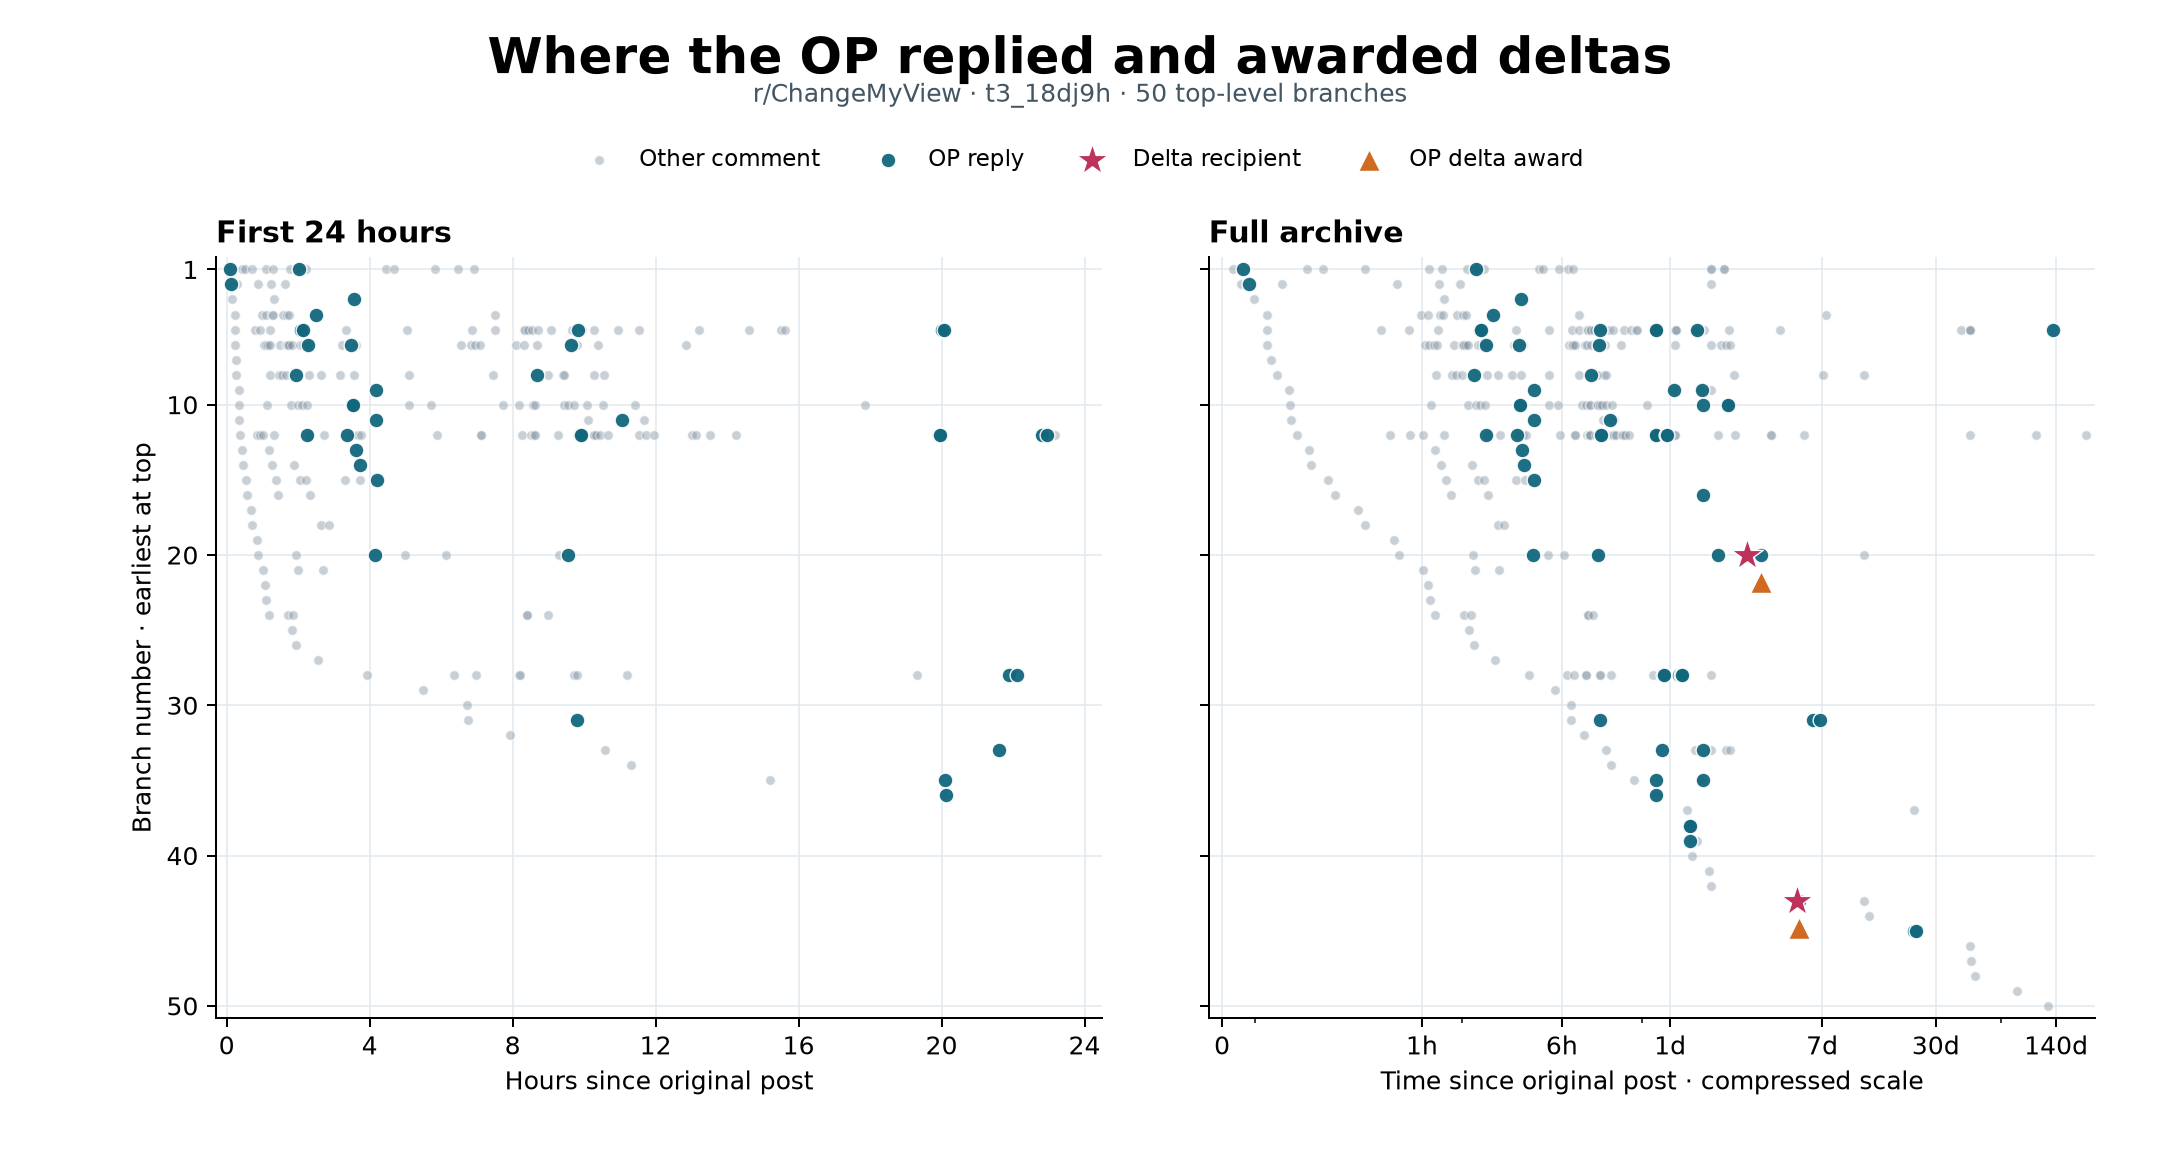

In [5]:
from matplotlib.transforms import offset_copy

# Order branch rows by opening time and reuse that order in both panels.
ordered_branches = (
    nodes.loc[nodes["depth"].eq(0)].reset_index().sort_values(
        ["created_utc", "node_id"], na_position="last"
    )["node_id"]
)
branch_positions = {branch_id: i for i, branch_id in enumerate(ordered_branches, start=1)}
plot_nodes = nodes.loc[nodes["linked_to_post"] & nodes["minutes_since_post"].ge(0)].copy()
plot_nodes["branch_row"] = plot_nodes["branch_id"].map(branch_positions)
plot_nodes = plot_nodes.dropna(subset=["branch_row"])

# The stars and triangles use different timestamps so the visual shows the wait for the award.
recipient_nodes = plot_nodes.loc[plot_nodes.index.isin(delta_awards["recipient_id"])]
award_nodes = plot_nodes.loc[plot_nodes.index.isin(delta_awards["award_id"])]
op_nodes = plot_nodes.loc[plot_nodes["is_op_reply"]]
other_nodes = plot_nodes.loc[~plot_nodes["is_op_reply"]]
layers = [
    (other_nodes, "Other comment", "o", "#8797a6", 15, 0.45),
    (op_nodes, "OP reply", "o", "#12677c", 35, 0.95),
    (recipient_nodes, "Delta recipient", "*", "#bd315a", 175, 1.0),
    (award_nodes, "OP delta award", "^", "#cf6a20", 77, 1.0),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), sharey=True)
fig.subplots_adjust(left=0.10, right=0.97, bottom=0.13, top=0.78, wspace=0.12)
fig.suptitle("Where the OP replied and awarded deltas", y=0.97, fontsize=20, fontweight="bold")
fig.text(0.5, 0.913, f"r/ChangeMyView · {POST_ID} · {len(ordered_branches)} top-level branches",
         ha="center", color="#455663", fontsize=10)

for ax, time_divisor, title in zip(axes, (60, 1), ("First 24 hours", "Full archive")):
    for frame, label, marker, color, marker_size, opacity in layers:
        # Offset award triangles slightly so a nearby award cannot cover its recipient star.
        marker_transform = (
            offset_copy(ax.transData, fig=fig, y=-11, units="points")
            if marker == "^" else ax.transData
        )
        ax.scatter(frame["minutes_since_post"] / time_divisor, frame["branch_row"],
                   label=label, marker=marker, c=color, s=marker_size,
                   alpha=opacity, linewidths=0.55, edgecolors="white",
                   zorder=4 if marker != "o" else 3, transform=marker_transform)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_axisbelow(True)
    ax.grid(color="#e3e9ee", linewidth=0.65)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(len(ordered_branches) + 0.8, 0.2)

axes[0].set(xlim=(-0.3, 24.5), xticks=range(0, 25, 4),
            xlabel="Hours since original post", ylabel="Branch number · earliest at top")
axes[0].set_yticks([1, *range(10, len(ordered_branches) + 1, 10)])
axes[1].set_xscale("symlog", linthresh=60)
full_ticks = [(0, "0"), (60, "1h"), (360, "6h"), (1440, "1d"),
              (10080, "7d"), (43200, "30d"), (201600, "140d")]
last_minute = plot_nodes["minutes_since_post"].max()
visible_ticks = [(tick, label) for tick, label in full_ticks if tick <= last_minute * 1.12]
axes[1].set_xticks([tick for tick, _ in visible_ticks], [label for _, label in visible_ticks])
axes[1].set(xlim=(-4, last_minute * 1.12), xlabel="Time since original post · compressed scale")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.89),
           ncol=4, frameon=False, fontsize=9)
figure_path = REPO_ROOT / "project/notebooks/nested-replies-analysis/op_engagement_timeline.png"
fig.savefig(figure_path, dpi=180, facecolor="white")
plt.show()

## Measure OP engagement

**Post clock.** Summarize OP activity in the first hour, the first 24 hours, and the full archive. Count a return when the OP switches to a branch they previously visited. Calculate concentration as the sum of squared branch shares of OP replies. The denominator for branch coverage is the number of openings visible by the cutoff.

**Branch clock.** Give each opening its own first hour and first 24 hours. Count comments below the opening and flag whether the OP replied. For the descriptive delta comparison, keep branches that had received no recorded OP delta by their 24-hour cutoff and count awards later in the available archive. The archive's follow-up can differ by branch. The counts describe this one discussion.

In [6]:
# Identify visits in time order. Repeated replies in the same branch are one visit.
ordered_op = op_timeline.dropna(subset=["branch_id", "minutes_since_post"]).copy()
ordered_op["starts_visit"] = ordered_op["branch_id"].ne(ordered_op["branch_id"].shift())
visits = ordered_op.loc[ordered_op["starts_visit"]].copy()
visits["is_return"] = visits["branch_id"].duplicated()

opening_minutes = nodes.loc[nodes["depth"].eq(0), "minutes_since_post"]
engagement_rows = []
for window, end_minute in [("First hour", 60), ("First 24 hours", 1440), ("Full archive", None)]:
    replies_in_window = ordered_op if end_minute is None else ordered_op.loc[
        ordered_op["minutes_since_post"].le(end_minute)
    ]
    visits_in_window = visits if end_minute is None else visits.loc[
        visits["minutes_since_post"].le(end_minute)
    ]
    reply_counts = replies_in_window["branch_id"].value_counts()
    branches_opened = len(opening_minutes) if end_minute is None else int(
        opening_minutes.le(end_minute).sum()
    )
    engagement_rows.append({
        "window": window,
        "branches_opened": branches_opened,
        "branches_with_op_reply": len(reply_counts),
        "share_of_branches_with_op_reply": len(reply_counts) / branches_opened if branches_opened else None,
        "op_replies": len(replies_in_window),
        "op_returns": int(visits_in_window["is_return"].sum()),
        "op_concentration": ((reply_counts / reply_counts.sum()) ** 2).sum() if len(reply_counts) else None,
    })

op_engagement = pd.DataFrame(engagement_rows).set_index("window")
display(op_engagement.round(3))

,branches_opened,branches_with_op_reply,share_of_branches_with_op_reply,op_replies,op_returns,op_concentration
window,,,,,,
First hour,20,2,0.100,2,0,0.500
First 24 hours,36,20,0.556,39,12,0.087
Full archive,50,25,0.500,63,24,0.064


In [7]:
# Attach each award to the recipient's top-level branch and retain the first award time.
awards_by_branch = delta_awards.assign(
    branch_id=delta_awards["recipient_id"].map(nodes["branch_id"])
).groupby("branch_id")["award_minutes"].min()

descendants = nodes.loc[nodes["depth"].gt(0)]
returns_by_branch = visits.loc[visits["is_return"], "branch_id"].value_counts()
# Group the descendants once. Branches with no descendants still get a row below.
descendants_by_branch = dict(iter(descendants.groupby("branch_id")))

branch_records = []
for branch_id, start_minute in opening_minutes.items():
    branch = descendants_by_branch.get(branch_id, descendants.iloc[0:0])
    elapsed = branch["minutes_since_post"] - start_minute
    op_comments = branch.loc[branch["is_op_reply"]]
    first_op_delay = (op_comments["minutes_since_post"] - start_minute).min()
    first_award_delay = awards_by_branch.get(branch_id, float("nan")) - start_minute
    record = {
        "branch_id": branch_id,
        "opening_minutes": start_minute,
        "first_op_delay_minutes": first_op_delay,
        "first_delta_delay_minutes": first_award_delay,
        "received_delta": branch_id in awards_by_branch.index,
        "comments_full": len(branch),
        "op_replies_full": len(op_comments),
        "op_returns_full": int(returns_by_branch.get(branch_id, 0)),
    }
    for window, minutes in [("1h", 60), ("24h", 1440)]:
        visible = branch.loc[elapsed.between(0, minutes)]
        record[f"comments_{window}"] = len(visible)
        record[f"op_replies_{window}"] = int(visible["is_op_reply"].sum())
    branch_records.append(record)

branch_engagement = pd.DataFrame(branch_records).set_index("branch_id")
# Rank across all openings. Branches with equal counts share the highest rank for that count.
for metric in ("comments_24h", "op_replies_24h", "op_replies_full", "op_returns_full"):
    branch_engagement[f"{metric}_rank"] = branch_engagement[metric].rank(
        ascending=False, method="min"
    ).astype(int)

print("Delta-winning branches and their ranks across all openings")
winner_columns = [
    "opening_minutes", "first_op_delay_minutes", "first_delta_delay_minutes",
    "comments_1h", "op_replies_1h", "comments_24h", "comments_24h_rank",
    "op_replies_24h", "op_replies_24h_rank", "op_replies_full", "op_replies_full_rank",
    "op_returns_full", "op_returns_full_rank",
]
display(branch_engagement.loc[branch_engagement["received_delta"], winner_columns].round(2))

# Compare branches that still had no delta after 24 hours, by volume and OP participation.
eligible = branch_engagement.loc[
    branch_engagement["opening_minutes"].notna()
    & (~branch_engagement["received_delta"] | branch_engagement["first_delta_delay_minutes"].gt(1440))
].copy()
eligible["later_delta"] = eligible["first_delta_delay_minutes"].gt(1440)
eligible["op_replied_24h"] = eligible["op_replies_24h"].gt(0)
eligible["comment_volume"] = pd.cut(
    eligible["comments_24h"], bins=[-1, 0, 2, 5, float("inf")],
    labels=["0", "1–2", "3–5", "6+"],
)

def later_delta_rates(by):
    counts = eligible.groupby(by, observed=True).agg(
        branches=("later_delta", "size"), later_deltas=("later_delta", "sum")
    )
    counts["later_delta_rate"] = counts["later_deltas"] / counts["branches"]
    return counts

print("Later delta rates by early comment volume")
display(later_delta_rates("comment_volume").round(3))
print("Later delta rates by early comment volume and OP participation")
display(later_delta_rates(["comment_volume", "op_replied_24h"]).round(3))

Delta-winning branches and their ranks across all openings


,opening_minutes,first_op_delay_minutes,first_delta_delay_minutes,comments_1h,op_replies_1h,comments_24h,comments_24h_rank,op_replies_24h,op_replies_24h_rank,op_replies_full,op_replies_full_rank,op_returns_full,op_returns_full_rank
branch_id,,,,,,,,,,,,,
t1_c8dtv3e,53.15,195.25,4582.82,0,0,6,9,2,5,4,5,3,3
t1_c8go2f3,7274.50,258.28,258.28,0,0,1,25,1,13,1,16,0,14


Later delta rates by early comment volume


,branches,later_deltas,later_delta_rate
comment_volume,,,
0,22,0,0.0
1–2,10,0,0.0
3–5,7,0,0.0
6+,10,1,0.1


Later delta rates by early comment volume and OP participation


branches  later_deltas  later_delta_rate
comment_volume op_replied_24h                                          
0              False                 22             0               0.0
1–2            False                  3             0               0.0
               True                   7             0               0.0
3–5            False                  1             0               0.0
               True                   6             0               0.0
6+             True                  10             1               0.1